In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

Мы будем работать с данными агрегатора такси [Sigma Cabs](https://www.kaggle.com/datasets/arashnic/taxi-pricing-with-mobility-analytics). В зависимости от характеристик поездки требуется предсказать один из трех типов повышенного ценообразования: [1, 2, 3]. Таким образом, это поможет компании оптимально мэтчить такси и клиентов. 

In [34]:
df = pd.read_csv('sigma_cabs.csv')
df.shape

(131662, 14)

In [35]:
# Занесем индекс колонку
df = df.set_index('Trip_ID')
df.head()

,Trip_Distance,Type_of_Cab,Customer_Since_Months,Life_Style_Index,Confidence_Life_Style_Index,Destination_Type,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Gender,Surge_Pricing_Type
Trip_ID,,,,,,,,,,,,,
T0005689460,6.77,B,1.0,2.42769,A,A,3.90500,0,40.0,46,60,Female,2
T0005689461,29.47,B,10.0,2.78245,B,A,3.45000,0,38.0,56,78,Male,2
T0005689464,41.58,NaN,10.0,NaN,NaN,E,3.50125,2,NaN,56,77,Male,2
T0005689465,61.56,C,10.0,NaN,NaN,A,3.45375,0,NaN,52,74,Male,3
T0005689467,54.95,C,10.0,3.03453,B,A,3.40250,4,51.0,49,102,Male,2


Описание признаков:

1. **Trip_ID**: ID for TRIP
2. **Trip_Distance**: The distance for the trip requested by the customer
3. **TypeofCab**: Category of the cab requested by the customer
4. **CustomerSinceMonths**: Customer using cab services since n months; 0 month means current month
5. **LifeStyleIndex**: Proprietary index created by Sigma Cabs showing lifestyle of the customer based on their behaviour
6. **ConfidenceLifeStyle_Index**: Category showing confidence on the index mentioned above
7. **Destination_Type**: Sigma Cabs divides any destination in one of the 14 categories.
8. **Customer_Rating**: Average of life time ratings of the customer till date
9. **CancellationLast1Month**: Number of trips cancelled by the customer in last 1 month
10. **Var1**, **Var2** and **Var3**: Continuous variables masked by the company. Can be used for modelling purposes
11. **Gender**: Gender of the customer

**SurgePricingType**: Target (can be of 3 types)


### EDA 
Заполните пропуски в вещественных признаках медианой, а в категориальных - самым популярным классом. Изобразите матрицу корреляций и выведите топ5 пар самых коррелированных признаков.

Так как в сумме уникальных значений различных категориальных признаков окажется не супер-много, примените `One-Hot-Encoding` для них. Не забудьте в методе `pd.get_dummies` указать параметр `drop_first=True`.

In [36]:
num_columns = df.drop('Surge_Pricing_Type', axis=1, errors='ignore').select_dtypes(include=['number']).columns
df[num_columns] = df[num_columns].fillna(df[num_columns].median())

str_columns = df.select_dtypes(include=['object']).columns
df[str_columns] = df[str_columns].fillna(df[str_columns].mode().iloc[0])

df = pd.get_dummies(df, drop_first=True)
df

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type,Type_of_Cab_B,...,Destination_Type_F,Destination_Type_G,Destination_Type_H,Destination_Type_I,Destination_Type_J,Destination_Type_K,Destination_Type_L,Destination_Type_M,Destination_Type_N,Gender_Male
Trip_ID,,,,,,,,,,,,,,,,,,,,,
T0005689460,6.77,1.0,2.42769,3.90500,0,40.0,46,60,2,True,...,False,False,False,False,False,False,False,False,False,False
T0005689461,29.47,10.0,2.78245,3.45000,0,38.0,56,78,2,True,...,False,False,False,False,False,False,False,False,False,True
T0005689464,41.58,10.0,2.79805,3.50125,2,61.0,56,77,2,True,...,False,False,False,False,False,False,False,False,False,True
T0005689465,61.56,10.0,2.79805,3.45375,0,61.0,52,74,3,False,...,False,False,False,False,False,False,False,False,False,True
T0005689467,54.95,10.0,3.03453,3.40250,4,51.0,49,102,2,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T0005908509,11.72,1.0,2.74229,3.28500,0,61.0,47,76,3,False,...,False,False,False,False,False,False,False,False,False,True
T0005908510,74.81,7.0,2.81059,0.44500,0,61.0,63,88,2,False,...,False,False,False,False,False,False,False,False,False,True
T0005908512,40.17,10.0,2.99565,3.33625,0,61.0,48,75,2,False,...,False,False,False,False,False,False,False,False,False,False


           feature_1      feature_2      corr
55              Var2           Var3  0.683437
16  Life_Style_Index  Trip_Distance  0.468332
23  Life_Style_Index           Var3  0.303324
30   Customer_Rating           Var2 -0.302968
7      Trip_Distance           Var3  0.231706


<Axes: >

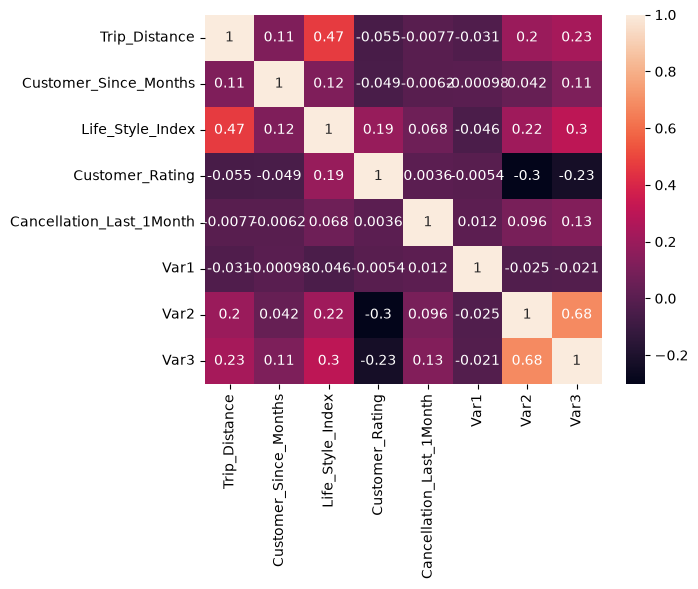

In [ ]:
# Мы берём здесь по num_columns потому что новые dummy столбцы 
# тоже по сути numeric и попали бы в корреляционную матрицу

X = df.drop('Surge_Pricing_Type', axis=1, errors='ignore')
y = df['Surge_Pricing_Type']

corr_matrix = df[num_columns].corr(numeric_only=True) 

a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])

c = corr_matrix.stack().reset_index()
c.columns = ['feature_1', 'feature_2', 'corr']
c = c[c['feature_1'] < c['feature_2']].sort_values(by='corr', ascending=False, key=abs).head(5)

print(c)

# С аннотацией (пометкой, пояснением) в каждой клетке
sns.heatmap(corr_matrix, annot=True)

### Training

In [38]:
np.random.seed(2022)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [39]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

**Задание 1.** Обучите One-vs-Rest Logreg. Не забудьте в шаг добавить стандартизацию данных (через `StandardScaler`) Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg. Здесь и далее округляйте до 3 знака после запятой.

Чтобы отдельно и долго не вычислять метрики, можно воспользоваться `classification_report` из `sklearn.metrics`!

In [41]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('one_vs_all', OneVsRestClassifier(LogisticRegression()))
])

pipe.fit(X_train, y_train)

# calibrated_classifier = CalibratedClassifierCV(pipe, cv=5, method='sigmoid')

# Посчитаем двумя способами метрики
# Через classification_report:
y_pred = pipe.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

# Через score-функции:
print()
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')

precision_micro = precision_score(y_test, y_pred, average='micro')
recall_micro = recall_score(y_test, y_pred, average='micro')
f1_micro = f1_score(y_test, y_pred, average='micro')

precision_weighted = precision_score(y_test, y_pred, average='weighted')
recall_weighted = recall_score(y_test, y_pred, average='weighted')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print('Precision macro: ', round(precision_macro, 3))
print('Recall macro: ', round(recall_macro, 3))
print('F1 macro: ', round(f1_macro, 3))

print('Precision micro: ', round(precision_micro, 3))
print('Recall micro: ', round(recall_micro, 3))
print('F1 micro: ', round(f1_micro, 3))

print('Precision weighted: ', round(precision_weighted, 3))
print('Recall weighted: ', round(recall_weighted, 3))
print('F1 weighted: ', round(f1_weighted, 3))

              precision    recall  f1-score   support

           1      0.723     0.542     0.619      5372
           2      0.636     0.834     0.722     11349
           3      0.741     0.571     0.645      9612

    accuracy                          0.679     26333
   macro avg      0.700     0.649     0.662     26333
weighted avg      0.692     0.679     0.673     26333


Precision macro:  0.7
Recall macro:  0.649
F1 macro:  0.662
Precision micro:  0.679
Recall micro:  0.679
F1 micro:  0.679
Precision weighted:  0.692
Recall weighted:  0.679
F1 weighted:  0.673


Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()` из предложенных. Для лучшего набора гиперпараметров посчитайте те же самые метрики. Валидировать параметры необходимо по `accuracy`. В этот раз проведем настояющую процедуру Кросс-Валидации! 

Для этого в метод `fit` передадим тренировочную часть наших данных, в параметр `cv` ничего не будем передавать (по дефолту 5-fold Кросс-Валидация будет проведена), а итоговые метрики замерим на тесте!

In [43]:
param_grid = {'one_vs_all__estimator__penalty': ['l1', 'l2', 'elasticnet'],
              'one_vs_all__estimator__C': [0.001, 0.01, 0.1, 1]}

In [45]:
from sklearn.model_selection import GridSearchCV

grid_ovr = GridSearchCV(pipe, param_grid=param_grid, cv=5)

grid_ovr.fit(X_train, y_train)

print(grid_ovr.best_params_)

print(classification_report(y_test, grid_ovr.predict(X_test), digits=3))

{'one_vs_all__estimator__C': 0.001, 'one_vs_all__estimator__penalty': 'l2'}
              precision    recall  f1-score   support

           1      0.742     0.534     0.621      5372
           2      0.635     0.839     0.723     11349
           3      0.742     0.576     0.649      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.664     26333
weighted avg      0.696     0.681     0.675     26333



Изобразите три калибровочные кривые для Logistic Classifier: 0-vs-rest, 1-vs-rest, 2-vs-rest. Хорошо ли откалиброван обученный классификатор? 

Заметьте, что `predict_proba` возвращает список из вероятностей для всех наших классов!

[3 2 2 ... 1 1 2]
[[0.30610812 0.27504635 0.41884552]
 [0.02307843 0.54055575 0.43636582]
 [0.02306692 0.55687828 0.4200548 ]
 ...
 [0.48664376 0.10498727 0.40836897]
 [0.56613335 0.18002436 0.25384229]
 [0.13873869 0.59993141 0.2613299 ]]


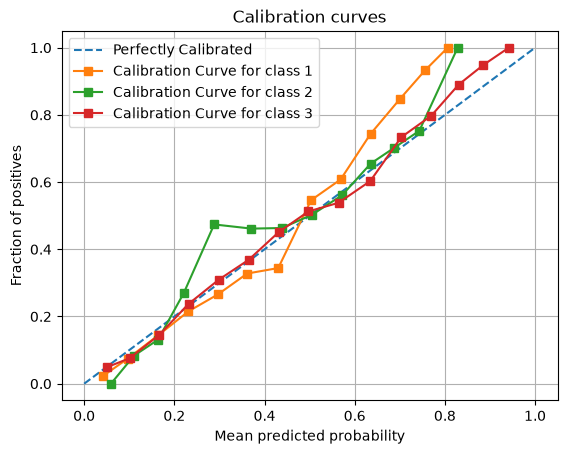

In [46]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, multilabel_confusion_matrix
import matplotlib.pyplot as plt

print(grid_ovr.predict(X_test))
y_test_1 = np.where(y_test == 1, 1, 0)
y_test_2 = np.where(y_test == 2, 1, 0)
y_test_3 = np.where(y_test == 3, 1, 0)

y_pred = grid_ovr.predict_proba(X_test)
print(y_pred)

frac_pos_1, mean_pred_proba_1 = calibration_curve(y_test_1, y_pred[:, 0], n_bins=15)
frac_pos_2, mean_pred_proba_2 = calibration_curve(y_test_2, y_pred[:, 1], n_bins=15)
frac_pos_3, mean_pred_proba_3 = calibration_curve(y_test_3, y_pred[:, 2], n_bins=15)

x = np.linspace(0, 1, 15)

plt.plot(x, x, label='Perfectly Calibrated', linestyle='--')
plt.plot(mean_pred_proba_1, frac_pos_1, marker='s', label='Calibration Curve for class 1')
plt.plot(mean_pred_proba_2, frac_pos_2, marker='s', label='Calibration Curve for class 2')
plt.plot(mean_pred_proba_3, frac_pos_3, marker='s', label='Calibration Curve for class 3')
plt.title('Calibration curves')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.grid()
plt.legend()

# Калибровка в целом неплохая

**Задание 2.** Обучите логистическую регрессию с гиперпараметрами из первого задания на полиномиальных признаках до 4 степени. Сравните метрики с первым заданием.


Пример: Пусть у нас был единственный признак 

$$
d_j = [1, 2, 3, 4]
$$

Тогда полиномиальные признаки до 4 степени от такого будут иметь вид:

$$
d_j^1 = [1, 2, 3, 4]
$$

$$
d_j^2 = [1, 4, 9, 16]
$$

$$
d_j^3 = [1, 8, 27, 64]
$$

$$
d_j^4 = [1, 16, 81, 256]
$$

P.S. Бинарные колонки нет смысла возводить в какие-то степени, поэтому возьмем исключительно вещественные из базовых. 

Для этого можно воспользоваться классическим циклом (или уроком из занятия про `Sberbank Housing Market`). Положите модифицированный датасет в переменную `X_polinomial`!

P.S.S Зачастую еще, создаваю полиномиальные фичи, учитывают "пересечения" признаков, то есть, например, из векторов признаков $d_j, d_i$ генерируют не просто новые степени $d_j^2, d_i^2, d_j^3, d_i^3...$, а еще и признаки вида $d_j \cdot d_i, d_j^2 \cdot d_i, d_j \cdot d_i^2...$, но здесь ограничьтесь просто степенями!

In [47]:
# from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

X_polinomial = X.copy()

def add_powers(X):
    X = np.asarray(X)

    return np.hstack([
        X, 
        X**2, 
        X**3,
        X**4
    ])

power_transformer = FunctionTransformer(add_powers)

preproccessor = ColumnTransformer(
    transformers=[
        ('powers', power_transformer, num_columns)
    ],
    remainder='passthrough'
)

pipe = Pipeline([
    # ('polynomial', PolynomialFeatures(4)),
    ('features', preproccessor),
    ('scaler', StandardScaler()),
    ('one_vs_all', OneVsRestClassifier(LogisticRegression(C=0.001, l1_ratio=0)))
])

In [48]:
X_pol_train, X_pol_test, y_train, y_test  = train_test_split(X_polinomial, y, 
                                                             test_size=0.2, 
                                                             shuffle=True, 
                                                             random_state=2022)

In [49]:
pipe.fit(X_pol_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['Trip_Distance','Customer_Since_Months','Life_Style_Index',..., 'Destination_Type_M','Destination_Type_N','Gender_Male']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('powers', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

По аналогии с первым заданием изобразите три калибровочные кривые. Стало ли лучше?

Неоднозначно.

              precision    recall  f1-score   support

           1      0.742     0.534     0.621      5372
           2      0.635     0.839     0.723     11349
           3      0.742     0.576     0.649      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.664     26333
weighted avg      0.696     0.681     0.675     26333

              precision    recall  f1-score   support

           1      0.748     0.532     0.622      5372
           2      0.636     0.837     0.723     11349
           3      0.741     0.584     0.653      9612

    accuracy                          0.682     26333
   macro avg      0.708     0.651     0.666     26333
weighted avg      0.697     0.682     0.677     26333



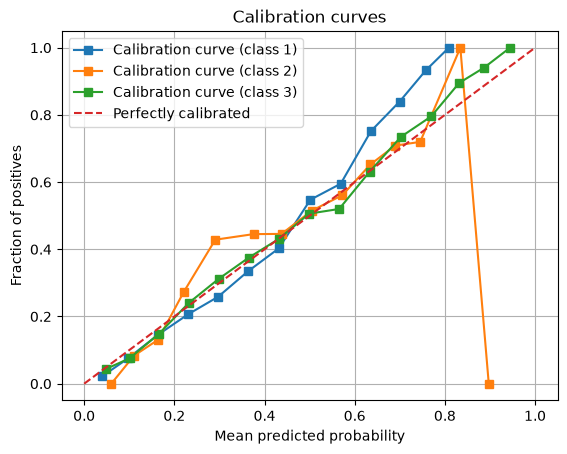

In [50]:
y_pred = pipe.predict_proba(X_pol_test)

for i in range(1, 4):
    y_true = np.where(y_test == i, 1, 0)
    fraction_of_positives, mean_pred_proba = calibration_curve(y_true, y_pred[:, i-1], n_bins=15)

    plt.plot(mean_pred_proba, fraction_of_positives, marker='s', label='Calibration curve (class ' + str(i) + ')')

x = np.linspace(0, 1, 15)
plt.plot(x, x, label='Perfectly calibrated', linestyle='--')
plt.title('Calibration curves')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.grid()
plt.legend()

print(classification_report(y_test, grid_ovr.predict(X_pol_test), digits=3))
print(classification_report(y_test, pipe.predict(X_pol_test), digits=3))


**Задание 3.** Обучите на датасете без полиномиальных признаков One-vs-One `SGDClassifier` из `sklearn.linear_model`, который использует стохастический градиентный спуск (узнаете о нем позже) и может обучать как `SVM`, так и, например, `LogReg`, если указать в качестве параметра `loss` либо `hinge`, либо `log` соответственно!

Посчитайте precision, recall, f1-score и усредните по всем классам с помощью micro, macro и weighted avg.

In [51]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                     test_size=0.2, 
                                                     shuffle=True, 
                                                     random_state=2022)

In [54]:
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsOneClassifier

np.random.seed(2022)

pipe_ovo = Pipeline([
    ('scaler', StandardScaler()),
    ('one_vs_one', OneVsOneClassifier(SGDClassifier()))
])

pipe_ovo.fit(X_train, y_train)

print(classification_report(y_test, pipe_ovo.predict(X_test), digits=3))

              precision    recall  f1-score   support

           1      0.748     0.521     0.614      5372
           2      0.626     0.870     0.728     11349
           3      0.756     0.536     0.627      9612

    accuracy                          0.677     26333
   macro avg      0.710     0.642     0.656     26333
weighted avg      0.698     0.677     0.668     26333



Подберите оптимальные гиперпараметры модели с помощью `GridSearchCV()`. При этом переберите всевозможные функции потерь. Таким образом, при `loss = 'hinge'`, мы обучим SVM, при `loss = 'log'` мы обучим логистическую регрессию и т.д.

Используйте прием с Кросс-Валидацией при подборе параметров, как ранее, а также замерьте метрики на тесте.

In [55]:
param_grid = {'one_vs_one__estimator__loss': ['hinge', 'log_loss', 'modified_huber'],
              'one_vs_one__estimator__penalty': ['l1', 'l2'],
              'one_vs_one__estimator__alpha': [0.001, 0.01, 0.1]}

In [56]:
grid_ovo = GridSearchCV(pipe_ovo, param_grid, cv=5) 

grid_ovo.fit(X_train, y_train)

print(f"Best parameters: {grid_ovo.best_params_}")

print("One-vs-Rest:")
print(classification_report(y_test, grid_ovr.predict(X_test), digits=3))

print("One-vs-One:")
print(classification_report(y_test, grid_ovo.predict(X_test), digits=3))


Best parameters: {'one_vs_one__estimator__alpha': 0.1, 'one_vs_one__estimator__loss': 'modified_huber', 'one_vs_one__estimator__penalty': 'l2'}
One-vs-Rest:
              precision    recall  f1-score   support

           1      0.742     0.534     0.621      5372
           2      0.635     0.839     0.723     11349
           3      0.742     0.576     0.649      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.664     26333
weighted avg      0.696     0.681     0.675     26333

One-vs-One:
              precision    recall  f1-score   support

           1      0.748     0.529     0.620      5372
           2      0.633     0.845     0.724     11349
           3      0.745     0.572     0.647      9612

    accuracy                          0.681     26333
   macro avg      0.709     0.649     0.663     26333
weighted avg      0.697     0.681     0.675     26333



Можно ли однозначно сказать, какой подход оказался лучше: One-vs-Rest или One-vs-One?

Большой разницы нет, в чем-то лучше немного одно, а в чем-то другое